In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [3]:
df = pd.read_csv(r"D:\OneDrive\Desktop\food\food_demand.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (456548, 15)


,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders,category,cuisine,city_code,region_code,center_type,op_area
0,1379560,1,55,1885,136.83,152.29,0,0,177,Beverages,Thai,647,56,TYPE_C,2.0
1,1466964,1,55,1993,136.83,135.83,0,0,270,Beverages,Thai,647,56,TYPE_C,2.0
2,1346989,1,55,2539,134.86,135.86,0,0,189,Beverages,Thai,647,56,TYPE_C,2.0
3,1338232,1,55,2139,339.50,437.53,0,0,54,Beverages,Indian,647,56,TYPE_C,2.0
4,1448490,1,55,2631,243.50,242.50,0,0,40,Beverages,Indian,647,56,TYPE_C,2.0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 456548 entries, 0 to 456547
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   id                     456548 non-null  int64  
 1   week                   456548 non-null  int64  
 2   center_id              456548 non-null  int64  
 3   meal_id                456548 non-null  int64  
 4   checkout_price         456548 non-null  float64
 5   base_price             456548 non-null  float64
 6   emailer_for_promotion  456548 non-null  int64  
 7   homepage_featured      456548 non-null  int64  
 8   num_orders             456548 non-null  int64  
 9   category               456548 non-null  str    
 10  cuisine                456548 non-null  str    
 11  city_code              456548 non-null  int64  
 12  region_code            456548 non-null  int64  
 13  center_type            456548 non-null  str    
 14  op_area                456548 non-null  float64

In [5]:
df.describe()

,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders,city_code,region_code,op_area
count,4.565480e+05,456548.000000,456548.000000,456548.000000,456548.000000,456548.000000,456548.000000,456548.00000,456548.000000,456548.000000,456548.000000,456548.000000
mean,1.250096e+06,74.768771,82.105796,2024.337458,332.238933,354.156627,0.081152,0.10920,261.872760,601.553399,56.614566,4.083590
std,1.443548e+05,41.524956,45.975046,547.420920,152.939723,160.715914,0.273069,0.31189,395.922798,66.195914,17.641306,1.091686
min,1.000000e+06,1.000000,10.000000,1062.000000,2.970000,55.350000,0.000000,0.00000,13.000000,456.000000,23.000000,0.900000
25%,1.124999e+06,39.000000,43.000000,1558.000000,228.950000,243.500000,0.000000,0.00000,54.000000,553.000000,34.000000,3.600000
50%,1.250184e+06,76.000000,76.000000,1993.000000,296.820000,310.460000,0.000000,0.00000,136.000000,596.000000,56.000000,4.000000
75%,1.375140e+06,111.000000,110.000000,2539.000000,445.230000,458.870000,0.000000,0.00000,324.000000,651.000000,77.000000,4.500000
max,1.499999e+06,145.000000,186.000000,2956.000000,866.270000,866.270000,1.000000,1.00000,24299.000000,713.000000,93.000000,7.000000


In [6]:
df.isnull().sum()

id                       0
week                     0
center_id                0
meal_id                  0
checkout_price           0
base_price               0
emailer_for_promotion    0
homepage_featured        0
num_orders               0
category                 0
cuisine                  0
city_code                0
region_code              0
center_type              0
op_area                  0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    
    print(col, ":", outliers)

id : 0
week : 0
center_id : 0
meal_id : 0
checkout_price : 1
base_price : 8
emailer_for_promotion : 37050
homepage_featured : 49855
num_orders : 32937
city_code : 0
region_code : 0
op_area : 51774


In [22]:
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    df[col] = df[col].clip(
        lower=lower,
        upper=upper
    )

print("Outliers handled successfully!")

Outliers handled successfully!


In [23]:
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    
    print(col, ":", outliers)

id : 0
week : 0
center_id : 0
meal_id : 0
checkout_price : 0
base_price : 0
emailer_for_promotion : 0
homepage_featured : 0
num_orders : 0
category : 0
cuisine : 0
city_code : 0
region_code : 0
center_type : 0
op_area : 0


In [24]:
df['Demand_Class'] = pd.qcut(
    df['num_orders'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

print(df['Demand_Class'].value_counts())

Demand_Class
Low       157711
High      150971
Medium    147866
Name: count, dtype: int64


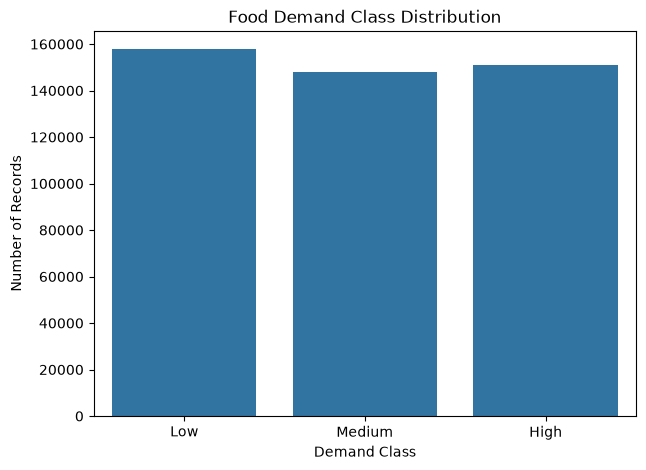

In [25]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Demand_Class'
)

plt.title("Food Demand Class Distribution")
plt.xlabel("Demand Class")
plt.ylabel("Number of Records")
plt.show()

In [26]:
categorical_cols = df.select_dtypes(include=['object']).columns

print("Categorical columns:")
print(categorical_cols.tolist())

Categorical columns:
[]


In [27]:
le = LabelEncoder()

for col in categorical_cols:
    df[col] = le.fit_transform(df[col].astype(str))

print("Categorical columns encoded successfully!")

Categorical columns encoded successfully!


In [28]:
df.head()

,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders,category,cuisine,city_code,region_code,center_type,op_area,Demand_Class
0,1379560,1,55,1885,136.83,152.29,0,0,177,0,3,647,56,2,2.25,Medium
1,1466964,1,55,1993,136.83,135.83,0,0,270,0,3,647,56,2,2.25,High
2,1346989,1,55,2539,134.86,135.86,0,0,189,0,3,647,56,2,2.25,Medium
3,1338232,1,55,2139,339.50,437.53,0,0,54,0,1,647,56,2,2.25,Low
4,1448490,1,55,2631,243.50,242.50,0,0,40,0,1,647,56,2,2.25,Low


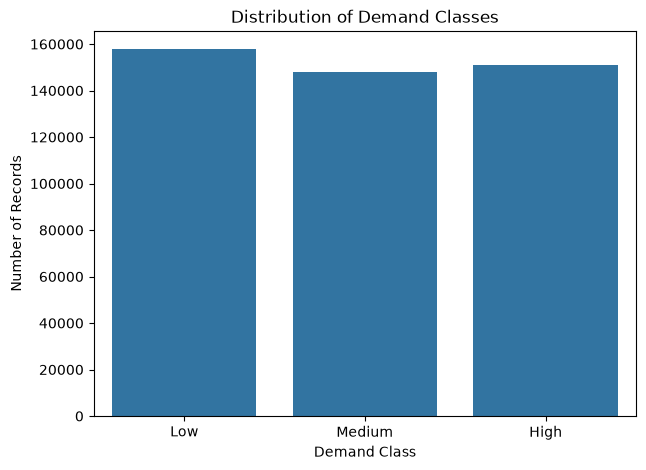

In [30]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x='Demand_Class')

plt.title("Distribution of Demand Classes")
plt.xlabel("Demand Class")
plt.ylabel("Number of Records")

plt.show()

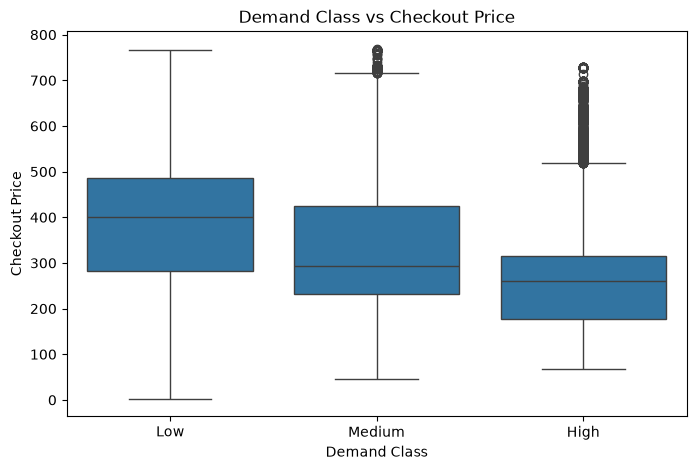

In [36]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='Demand_Class',
    y='checkout_price'
)

plt.title("Demand Class vs Checkout Price")
plt.xlabel("Demand Class")
plt.ylabel("Checkout Price")

plt.show()

In [39]:
le = LabelEncoder()

df['Demand_Class'] = le.fit_transform(df['Demand_Class'])

print(df['Demand_Class'].value_counts())

Demand_Class
1    157711
0    150971
2    147866
Name: count, dtype: int64


In [41]:
X = df.drop(['num_orders', 'Demand_Class'], axis=1)

y = df['Demand_Class']

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print("Demand_Class")

Features:
['id', 'week', 'center_id', 'meal_id', 'checkout_price', 'base_price', 'emailer_for_promotion', 'homepage_featured', 'category', 'cuisine', 'city_code', 'region_code', 'center_type', 'op_area']

Target:
Demand_Class


In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (365238, 14)
Testing data: (91310, 14)


In [43]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest Classifier trained successfully!")

Random Forest Classifier trained successfully!


In [44]:
y_pred = rf_model.predict(X_test)

print("Predictions generated successfully!")

print("\nFirst 20 predictions:")
print(y_pred[:20])

Predictions generated successfully!

First 20 predictions:
[0 1 2 2 1 1 0 2 2 1 1 1 2 2 1 1 1 2 2 2]


In [45]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy %:", accuracy * 100)

Accuracy: 0.7912057824991786
Accuracy %: 79.12057824991786


In [46]:
print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred
    )
)

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.87      0.86     30194
           1       0.83      0.83      0.83     31543
           2       0.69      0.67      0.68     29573

    accuracy                           0.79     91310
   macro avg       0.79      0.79      0.79     91310
weighted avg       0.79      0.79      0.79     91310



In [50]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[26223    75  3896]
 [  163 26128  5252]
 [ 4243  5436 19894]]


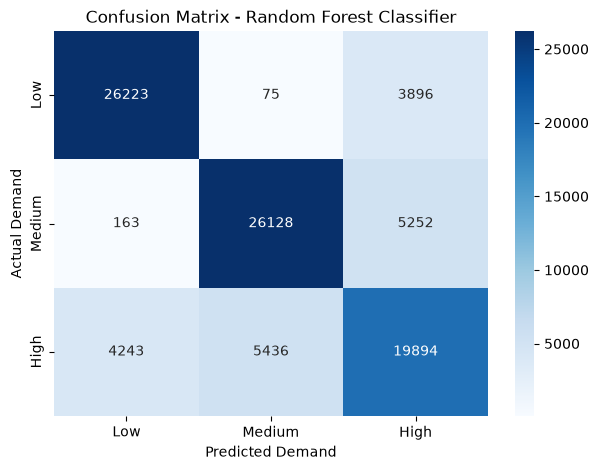

In [51]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.xlabel("Predicted Demand")
plt.ylabel("Actual Demand")
plt.title("Confusion Matrix - Random Forest Classifier")

plt.show()

In [52]:
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

results.head(20)

,Actual,Predicted
0,2,0
1,1,1
2,2,2
3,2,2
4,1,1
5,1,1
6,0,0
7,0,2
8,2,2
9,1,1


In [53]:
results.to_csv(
    "food_demand_classification_results.csv",
    index=False
)

print("Prediction results saved successfully!")

Prediction results saved successfully!


In [54]:
import joblib

joblib.dump(
    rf_model,
    "food_demand_random_forest_classifier.pkl"
)

print("Random Forest Classifier saved successfully!")

Random Forest Classifier saved successfully!
